# Academic Survival Dataset – Beginner Question Set
**Level:** Easy | **Questions:** 25

**Dataset:** `academic_survival.csv`

**Instructions:** Solve each question in the code cell below it. Keep your code clean, readable, and simple!

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

In [56]:
df=pd.read_csv("academic_survival.csv")

### Q1. Load the dataset and find its size
Load the CSV file into a pandas DataFrame named `df` and display the number of rows and columns.

In [57]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('academic_survival.csv')

# Print the shape
print("Dataset Shape:", df.shape)

Dataset Shape: (79239, 22)


### Q2. Check for missing values
Count how many missing values are in each column of the DataFrame.

In [58]:
# Count missing values per column
missing_counts = df.isnull().sum()
print(missing_counts)

Student_ID                    0
Age                           0
Gender                        0
First_Generation              0
Family_Income              3604
Household_Size                0
Housing_Status                0
Scholarship                   0
Tuition_Base                  0
Semester                      0
Course_Load                   0
Work_Hours                    0
Emergency_Expense             0
Sem_GPA                       0
Attendance                    0
LMS_Logins                  867
Advising_Visits               0
Failed_Courses                0
Financial_Stress              0
Target_Dropout_Next_Sem       0
End_of_Semester_Status        0
Censored                      0
dtype: int64


### Q3. Standardize Gender labels
Replace lowercase or single-letter gender labels (like 'female', 'f', 'F') with 'Female', and ('male', 'm', 'M') with 'Male'. Print the new value counts.

In [59]:
# Standardize using a simple map dictionary
gender_map = {
    'female': 'Female', 'f': 'Female', 'F': 'Female', 'Female': 'Female',
    'male': 'Male', 'm': 'Male', 'M': 'Male', 'Male': 'Male'
}
df['Gender'] = df['Gender'].map(gender_map).fillna('Other')
print(df['Gender'].value_counts())

Gender
Female    39626
Male      38059
Other      1554
Name: count, dtype: int64


### Q4. Fill missing values with the average
Fill all missing values in the `Family_Income` column with its mean (average) value.

In [60]:
# Calculate mean
mean_income = df['Family_Income'].mean()

# Fill missing values
df['Family_Income'] = df['Family_Income'].fillna(mean_income)
print("Missing values left in Family_Income:", df['Family_Income'].isnull().sum())

Missing values left in Family_Income: 0


### Q5. Filter extreme values in Attendance
Keep only rows where `Attendance` is between 0 and 100 percent.

In [61]:
# Filter rows
df = df[(df['Attendance'] >= 0) & (df['Attendance'] <= 100)]
print("Attendance range:", df['Attendance'].min(), "to", df['Attendance'].max())

Attendance range: 58.7 to 100.0


### Q6. Find the overall average GPA
Calculate and print the overall average of the `Sem_GPA` column.

In [62]:
average_gpa = df['Sem_GPA'].mean()
print("Average GPA:", average_gpa)

Average GPA: 2.6914980377262947


### Q7. Find average GPA by Housing Status
Group by `Housing_Status` and print the mean `Sem_GPA` for each housing group.

In [63]:
gpa_by_housing = df.groupby('Housing_Status')['Sem_GPA'].mean()
print(gpa_by_housing)

Housing_Status
Off-Campus      2.678471
On-Campus       2.678837
With Parents    2.719693
Name: Sem_GPA, dtype: float64


### Q8. Count the number of low GPA students
Count how many students have a `Sem_GPA` less than 2.0.

In [64]:
low_gpa_count = (df['Sem_GPA'] < 2.0).sum()
print("Students with GPA < 2.0:", low_gpa_count)

Students with GPA < 2.0: 4164


### Q9. Create a column indicating if a student dropped out
Create a new column `Is_Dropout` which contains 1 if `End_of_Semester_Status` is 'Dropped_Out', and 0 otherwise.

In [65]:
df['Is_Dropout'] = np.where(df['End_of_Semester_Status'] == 'Dropped_Out', 1, 0)
print(df['Is_Dropout'].value_counts())

Is_Dropout
0    72096
1     6894
Name: count, dtype: int64


### Q10. Count dropouts by Scholarship status
Show how many dropouts there are among students with and without a scholarship.

In [66]:
dropout_by_scholarship = df.groupby('Scholarship')['Is_Dropout'].sum()
print(dropout_by_scholarship)

Scholarship
0    5529
1    1365
Name: Is_Dropout, dtype: int64


### Q11. Draw a simple histogram of GPA
Plot a basic histogram showing the distribution of `Sem_GPA`.

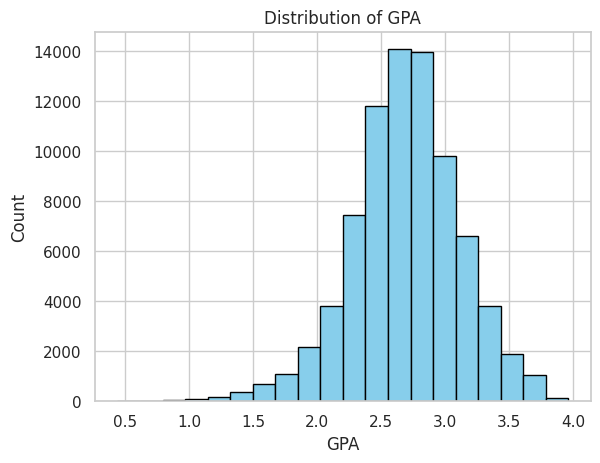

In [67]:
import matplotlib.pyplot as plt

plt.hist(df['Sem_GPA'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of GPA')
plt.xlabel('GPA')
plt.ylabel('Count')
plt.show()

### Q12. Create simple Work Hours categories
Create a `Work_Category` column: 'Low' if Work_Hours <= 15, and 'High' if Work_Hours > 15.

In [68]:
df['Work_Category'] = np.where(df['Work_Hours'] <= 15, 'Low', 'High')
print(df['Work_Category'].value_counts())

Work_Category
High    43125
Low     35865
Name: count, dtype: int64


### Q13. Find the correlation between GPA and Attendance
Calculate the simple correlation coefficient between `Sem_GPA` and `Attendance`.

In [69]:
correlation = df['Sem_GPA'].corr(df['Attendance'])
print("Correlation:", correlation)

Correlation: 0.30611977343525265


### Q14. Plot GPA vs Attendance
Create a scatter plot of `Attendance` on the x-axis and `Sem_GPA` on the y-axis.

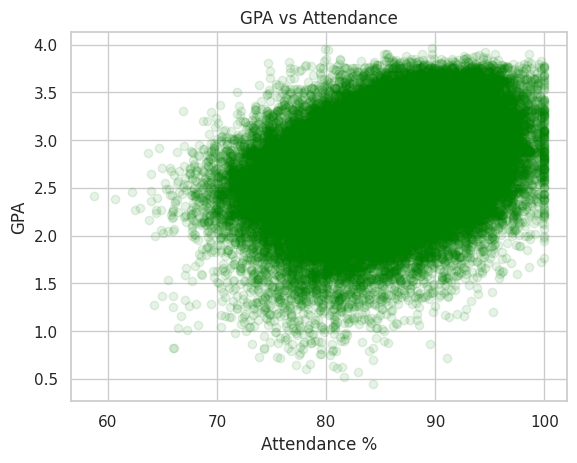

In [70]:
plt.scatter(df['Attendance'], df['Sem_GPA'], alpha=0.1, color='green')
plt.title('GPA vs Attendance')
plt.xlabel('Attendance %')
plt.ylabel('GPA')
plt.show()

### Q15. Create a smaller sample
Create a new DataFrame `sample_df` with 1000 randomly selected rows.

In [71]:
sample_df = df.sample(n=1000, random_state=42)
print("Sample size:", sample_df.shape)

Sample size: (1000, 24)


### Q16. Plot GPA line chart by Semester
Calculate the average GPA for each Semester and plot it as a line chart.

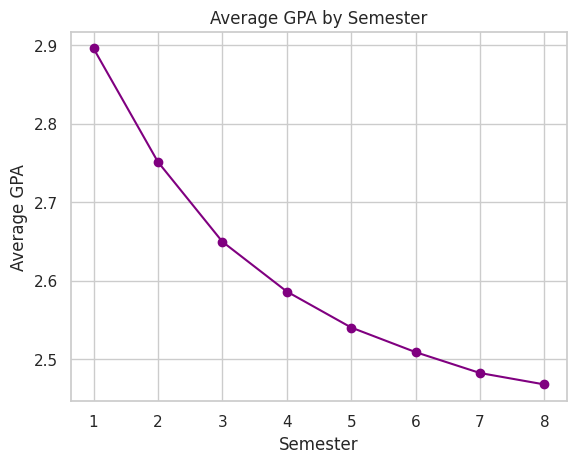

In [72]:
gpa_by_semester = df.groupby('Semester')['Sem_GPA'].mean()
plt.plot(gpa_by_semester.index, gpa_by_semester.values, marker='o', color='purple')
plt.title('Average GPA by Semester')
plt.xlabel('Semester')
plt.ylabel('Average GPA')
plt.grid(True)
plt.show()

### Q17. Draw a bar chart of End of Semester Status
Plot a bar chart showing the count of students in each category of `End_of_Semester_Status`.

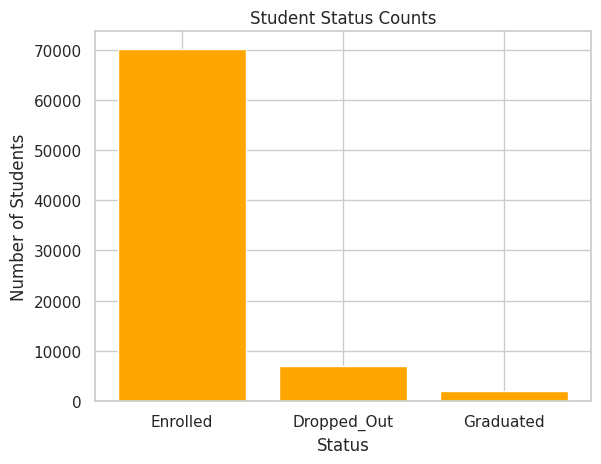

In [73]:
status_counts = df['End_of_Semester_Status'].value_counts()
plt.bar(status_counts.index, status_counts.values, color='orange')
plt.title('Student Status Counts')
plt.xlabel('Status')
plt.ylabel('Number of Students')
plt.show()

### Q18. Dropout rate by Semester
Find the percentage of students who drop out in each `Semester`.

In [74]:
dropout_by_sem = df.groupby('Semester')['Is_Dropout'].mean() * 100
print(dropout_by_sem)

Semester
1     6.659312
2     8.853569
3     9.757392
4     9.289564
5    10.006515
6     9.400938
7    10.021436
8     9.411219
Name: Is_Dropout, dtype: float64


### Q19. Compare GPA: First Gen vs Non-First Gen
Find the average `Sem_GPA` for students who are First Generation college students (1) versus those who are not (0).

In [75]:
gpa_by_gen = df.groupby('First_Generation')['Sem_GPA'].mean()
print(gpa_by_gen)

First_Generation
0    2.684256
1    2.706347
Name: Sem_GPA, dtype: float64


### Q20. Find average GPA for low attendance students
Find the average GPA of students who have an `Attendance` score of less than 80%.

In [76]:
low_attendance_gpa = df[df['Attendance'] < 80]['Sem_GPA'].mean()
print("Average GPA of low attendance students:", low_attendance_gpa)

Average GPA of low attendance students: 2.5003363367494327


### Q21. Count of students per Semester
Count how many records exist for each semester.

In [77]:
records_per_semester = df['Semester'].value_counts().sort_index()
print(records_per_semester)

Semester
1    19942
2    16547
3    13190
4    10205
5     7675
6     5542
7     3732
8     2157
Name: count, dtype: int64


### Q22. Average Advising Visits
Find the mean number of advising visits students make.

In [78]:
mean_visits = df['Advising_Visits'].mean()
print("Average Advising Visits:", mean_visits)

Average Advising Visits: 0.47754146094442335


### Q23. Average GPA by Gender
Calculate and print the average GPA for each gender group.

In [79]:
gpa_by_gender = df.groupby('Gender')['Sem_GPA'].mean()
print(gpa_by_gender)

Gender
Female    2.689121
Male      2.694223
Other     2.685380
Name: Sem_GPA, dtype: float64


### Q24. Find the highest GPA
Find and print the highest single GPA in the dataset.

In [80]:
max_gpa = df['Sem_GPA'].max()
print("Highest GPA:", max_gpa)

Highest GPA: 3.96


### Q25. Basic boxplot of GPA by Scholarship
Create a boxplot comparing `Sem_GPA` between students who have a scholarship and those who do not.

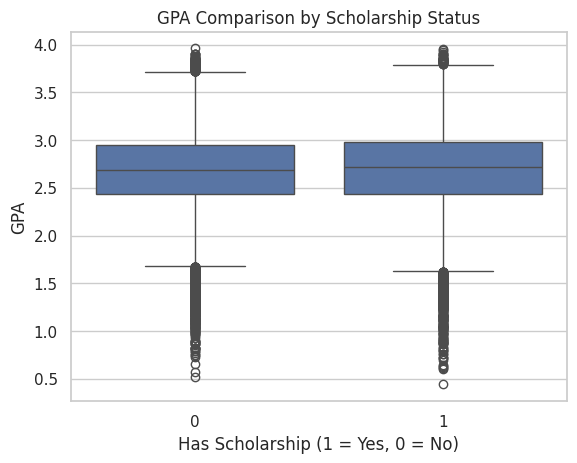

In [81]:
import seaborn as sns

sns.boxplot(x='Scholarship', y='Sem_GPA', data=df)
plt.title('GPA Comparison by Scholarship Status')
plt.xlabel('Has Scholarship (1 = Yes, 0 = No)')
plt.ylabel('GPA')
plt.show()

---
### End of Question Set
Bonus: write 3 insights you found about which students are most likely to drop out.